# Fine tuning basics: teach a tiny model a new skill without breaking the old one
This notebook trains a tiny numpy neural network on task A, then fine tunes it on task B and shows how badly it forgets task A along the way. It then repeats the fine tune with a small share of task A examples mixed back in, which is called replay, and shows how that protects the old skill.

## Step 0: Setup
Only numpy, pandas and matplotlib. Everything is generated in code with a fixed seed, so you get the same numbers I did.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

## Step 1: Make two toy tasks (simulated data)
All the data here is simulated. Each task is a set of 2D points split into two classes.

* **Task A** lives on the left side (x around -2). Points at the top are class 1, points at the bottom are class 0.
* **Task B** lives on the right side (x around +2). Here the rule is flipped: top is class 0, bottom is class 1.

One network can learn both, because it can look at x to tell which task it is in. But if you only ever show it task B, the cheapest fix is to flip its "top means 1" habit everywhere. That is exactly the kind of quiet damage the post is about.

In [2]:
def make_task(x_center, top_label, n):
    half = n // 2
    top = rng.normal([x_center, 1.5], 0.6, size=(half, 2))
    bottom = rng.normal([x_center, -1.5], 0.6, size=(half, 2))
    X = np.vstack([top, bottom])
    y = np.concatenate([np.full(half, top_label), np.full(half, 1 - top_label)])
    return X, y

XA_train, yA_train = make_task(-2.0, top_label=1, n=200)
XA_test, yA_test = make_task(-2.0, top_label=1, n=200)
XB_train, yB_train = make_task(2.0, top_label=0, n=200)
XB_test, yB_test = make_task(2.0, top_label=0, n=200)

print("Task A train/test points:", len(XA_train), len(XA_test))
print("Task B train/test points:", len(XB_train), len(XB_test))

Task A train/test points: 200 200
Task B train/test points: 200 200


## Step 2: A tiny neural network in numpy
The model is two small layers: 2 inputs, 16 hidden units, 1 output that says "probability of class 1". The **weights** are just a few numpy arrays.

Training means: show the model a small batch of points, see how wrong it is, and nudge every weight a little to be less wrong. One **epoch** is one pass over the training data.

In [3]:
def init_params(seed_rng, hidden=16):
    return {
        "W1": seed_rng.normal(0, 0.5, (2, hidden)),
        "b1": np.zeros(hidden),
        "W2": seed_rng.normal(0, 0.5, (hidden, 1)),
        "b2": np.zeros(1),
    }

def forward(p, X):
    h = np.tanh(X @ p["W1"] + p["b1"])
    out = 1 / (1 + np.exp(-(h @ p["W2"] + p["b2"])))
    return h, out.ravel()

def accuracy(p, X, y):
    return float(((forward(p, X)[1] > 0.5) == y).mean())

def train_epoch(p, X, y, lr=0.3, batch=20):
    idx = rng.permutation(len(X))
    for start in range(0, len(X), batch):
        b = idx[start:start + batch]
        xb, yb = X[b], y[b]
        h, out = forward(p, xb)
        g = (out - yb)[:, None] / len(xb)          # gradient of the loss at the output
        dh = (g @ p["W2"].T) * (1 - h ** 2)        # pushed back through tanh
        p["W2"] -= lr * (h.T @ g)
        p["b2"] -= lr * g.sum(axis=0)
        p["W1"] -= lr * (xb.T @ dh)
        p["b1"] -= lr * dh.sum(axis=0)

def copy_params(p):
    return {k: v.copy() for k, v in p.items()}

## Step 3: "Pretrain" on task A
This is our stand-in for pretraining: the model learns its first skill, task A. We never show it task B here, so on task B it should be roughly hopeless, or even backwards, since task B uses the flipped rule.

In [4]:
base = init_params(rng)
for epoch in range(30):
    train_epoch(base, XA_train, yA_train)

before_A = accuracy(base, XA_test, yA_test)
before_B = accuracy(base, XB_test, yB_test)
print(f"After training on A only -> task A accuracy: {before_A:.2f}, task B accuracy: {before_B:.2f}")

After training on A only -> task A accuracy: 0.99, task B accuracy: 0.01


## Step 4: Fine tune on task B only, and watch task A
Now the fine tune. We copy the trained model and train it only on task B. After every epoch we score it on **both** test sets. This is the "do not break" habit from the post: always check the old skill too, not just the new one.

In [5]:
def fine_tune(start_params, X_train, y_train, epochs=25):
    p = copy_params(start_params)
    history = [(0, accuracy(p, XA_test, yA_test), accuracy(p, XB_test, yB_test))]
    for epoch in range(1, epochs + 1):
        train_epoch(p, X_train, y_train)
        history.append((epoch, accuracy(p, XA_test, yA_test), accuracy(p, XB_test, yB_test)))
    return p, pd.DataFrame(history, columns=["epoch", "acc_A", "acc_B"])

plain_model, plain_hist = fine_tune(base, XB_train, yB_train)
print(plain_hist.iloc[[0, 1, 2, 5, 10, 25]].round(2).to_string(index=False))

 epoch  acc_A  acc_B
     0    1.0    0.0
     1    0.0    1.0
     2    0.0    1.0
     5    0.0    1.0
    10    0.0    1.0
    25    0.0    1.0


### Chart 1: the new skill goes up, the old one falls off a cliff
Task B climbs quickly, which is what we wanted. Task A, which the model knew well a moment ago, slides down at the same time. Nothing in the training told the model to forget A. It just got pushed hard in one direction.

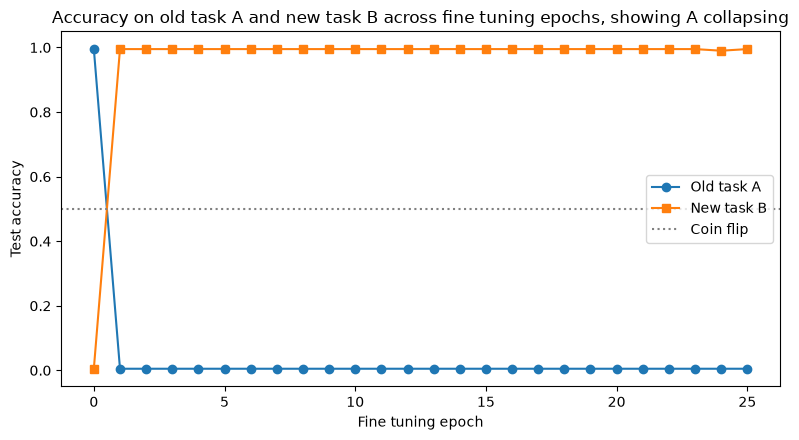

In [6]:
plt.figure(figsize=(8, 4.5))
plt.plot(plain_hist["epoch"], plain_hist["acc_A"], marker="o", label="Old task A")
plt.plot(plain_hist["epoch"], plain_hist["acc_B"], marker="s", label="New task B")
plt.axhline(0.5, color="gray", linestyle=":", label="Coin flip")
plt.xlabel("Fine tuning epoch")
plt.ylabel("Test accuracy")
plt.ylim(-0.05, 1.05)
plt.legend()
plt.title("Accuracy on old task A and new task B across fine tuning epochs, showing A collapsing")
plt.tight_layout()
plt.show()

## Step 5: Fine tune again, with replay
Same starting model, same task B data, but this time I mix in a small share of task A examples: 50 task A points next to 200 task B points. That is the "mix in normal examples" item from the checklist. The model keeps getting a little reminder of the old skill while it learns the new one.

In [7]:
replay_idx = rng.choice(len(XA_train), size=50, replace=False)
X_mix = np.vstack([XB_train, XA_train[replay_idx]])
y_mix = np.concatenate([yB_train, yA_train[replay_idx]])

replay_model, replay_hist = fine_tune(base, X_mix, y_mix)
print(f"Replay share: {len(replay_idx)} task A points out of {len(X_mix)} training points "
      f"({len(replay_idx) / len(X_mix):.0%})")
print(replay_hist.iloc[[0, 1, 2, 5, 10, 25]].round(2).to_string(index=False))

Replay share: 50 task A points out of 250 training points (20%)
 epoch  acc_A  acc_B
     0   1.00   0.00
     1   0.08   0.99
     2   0.14   0.99
     5   0.88   0.99
    10   0.98   1.00
    25   1.00   1.00


### Chart 2: one setting changed, very different outcome
Here I only plot the old task A score. The only difference between the two lines is whether a few task A examples were mixed in during fine tuning.

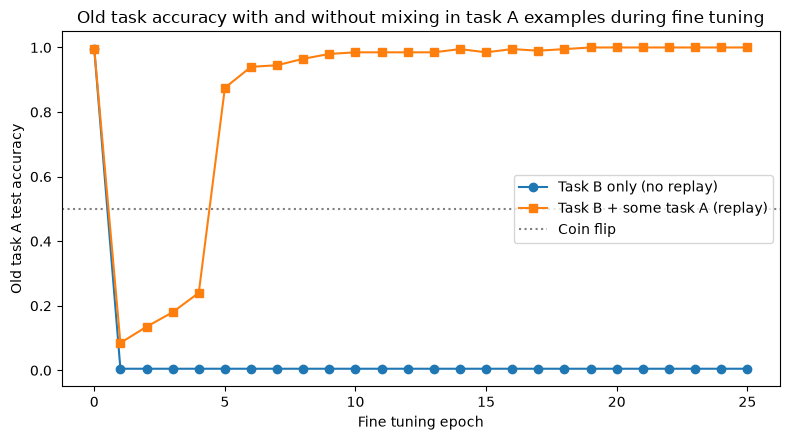

In [8]:
plt.figure(figsize=(8, 4.5))
plt.plot(plain_hist["epoch"], plain_hist["acc_A"], marker="o", label="Task B only (no replay)")
plt.plot(replay_hist["epoch"], replay_hist["acc_A"], marker="s", label="Task B + some task A (replay)")
plt.axhline(0.5, color="gray", linestyle=":", label="Coin flip")
plt.xlabel("Fine tuning epoch")
plt.ylabel("Old task A test accuracy")
plt.ylim(-0.05, 1.05)
plt.legend()
plt.title("Old task accuracy with and without mixing in task A examples during fine tuning")
plt.tight_layout()
plt.show()

## Step 6: The before and after check
This is the measurement from the post: **forgetting = old task score before minus old task score after**. I score both tasks before fine tuning and after each version of the fine tune.

In [9]:
after_plain = (accuracy(plain_model, XA_test, yA_test), accuracy(plain_model, XB_test, yB_test))
after_replay = (accuracy(replay_model, XA_test, yA_test), accuracy(replay_model, XB_test, yB_test))

summary = pd.DataFrame(
    {
        "Before fine tune": [before_A, before_B],
        "After fine tune (no replay)": list(after_plain),
        "After fine tune (with replay)": list(after_replay),
    },
    index=["Task A (old)", "Task B (new)"],
)
print(summary.round(2))
print()
print(f"Forgetting on task A without replay: {before_A - after_plain[0]:.2f}")
print(f"Forgetting on task A with replay:    {before_A - after_replay[0]:.2f}")

              Before fine tune  After fine tune (no replay)  \
Task A (old)               1.0                          0.0   
Task B (new)               0.0                          1.0   

              After fine tune (with replay)  
Task A (old)                            1.0  
Task B (new)                            1.0  

Forgetting on task A without replay: 0.99
Forgetting on task A with replay:    -0.01


### Chart 3: the whole story in one picture
Left group is the old task, right group is the new task. You want the new task bar to go up and the old task bar to stay put. Only the replay run does both.

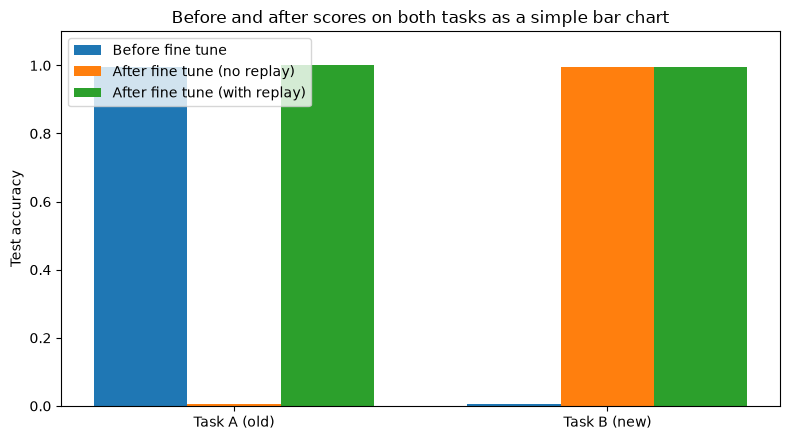

In [10]:
labels = summary.index.tolist()
x = np.arange(len(labels))
width = 0.25

plt.figure(figsize=(8, 4.5))
for i, col in enumerate(summary.columns):
    plt.bar(x + (i - 1) * width, summary[col], width, label=col)
plt.xticks(x, labels)
plt.ylabel("Test accuracy")
plt.ylim(0, 1.1)
plt.legend(loc="upper left")
plt.title("Before and after scores on both tasks as a simple bar chart")
plt.tight_layout()
plt.show()

## What to take away
The tiny network did exactly what the post warns about. Trained only on the new task, it got good at B and lost A, even though nobody asked it to forget anything. Both skills live in the same weights, so pushing on one moved the other.

Mixing a small share of old examples back in kept task A mostly intact while B was still learned. A real fine tune of a large model is far more complex than this toy, but the habit carries over: score the old skills before you train, mix some of them into your training data, and score them again afterwards.